# PedalHora | Demo Day de IA
**Desafio 3 · Prever aluguel de bicicletas**

O cliente é a equipe de operações do Capital Bikeshare. Quando a demanda sobe, a equipe precisa planejar a disponibilidade de bicicletas. A PedalHora estima o total de aluguéis da rede durante uma hora, com base no calendário e no cenário meteorológico. O protótipo ajuda a identificar horários que merecem atenção, em uma simulação com dados históricos.

**Fonte:** Fanaee-T e Gama, [Bike Sharing (UCI)](https://doi.org/10.24432/C5W894). Usamos os registros horários de 2011–2012 incluídos em `dados/hour.csv`.

## 1. Conhecer os dados
Ordenamos os registros por data e hora e separamos cerca de 60% para treino, 20% para validação e 20% para teste. A separação cronológica faz a validação e o teste simularem períodos futuros. Os dois gráficos usam exclusivamente o treino.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

from pathlib import Path
import json

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

from previsao import preparar

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()

df = (pd.read_csv("dados/hour.csv", parse_dates=["dteday"])
      .sort_values(["dteday", "hr"]).reset_index(drop=True))
corte_treino, corte_valid = int(len(df) * .6), int(len(df) * .8)
treino = df.iloc[:corte_treino]
validacao = df.iloc[corte_treino:corte_valid]
teste = df.iloc[corte_valid:]
for nome, parte in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]:
    print(f"{nome}: {len(parte):,} horas | {parte.dteday.iloc[0]:%d/%m/%Y} a "
          f"{parte.dteday.iloc[-1]:%d/%m/%Y}")
display(treino[["dteday", "hr", "weathersit", "temp", "cnt"]].head())

      dteday  hr  weathersit  temp  cnt
0 2011-01-01   0           1  0.24   16
1 2011-01-01   1           1  0.22   40
2 2011-01-01   2           1  0.22   32
3 2011-01-01   3           1  0.24   13
4 2011-01-01   4           1  0.24    1

Treino: 10,427 horas | 01/01/2011 a 15/03/2012
Validação: 3,476 horas | 15/03/2012 a 07/08/2012
Teste: 3,476 horas | 07/08/2012 a 31/12/2012


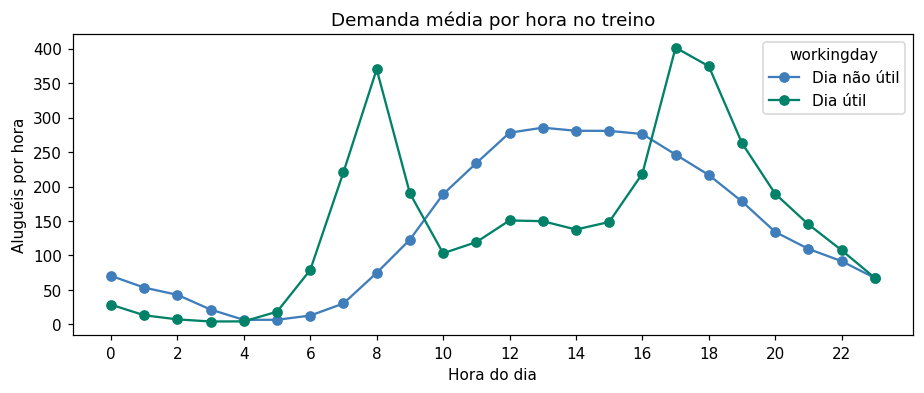

Em dias úteis, a maior média ocorre às 17h; nos demais dias, às 13h.


In [2]:
perfil = treino.groupby(["hr", "workingday"]).cnt.mean().unstack()
ax = perfil.rename(columns={0: "Dia não útil", 1: "Dia útil"}).plot(
    marker="o", color=["#3f7dbb", "#008168"], figsize=(8.5, 3.7))
ax.set(title="Demanda média por hora no treino", xlabel="Hora do dia",
       ylabel="Aluguéis por hora")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
from io import BytesIO
from IPython.display import Image
imagem = BytesIO()
ax.figure.savefig(imagem, format='png', dpi=110, bbox_inches='tight')
display(Image(data=imagem.getvalue()))
plt.close(ax.figure)
print(f"Em dias úteis, a maior média ocorre às {perfil[1].idxmax()}h; "
      f"nos demais dias, às {perfil[0].idxmax()}h.")

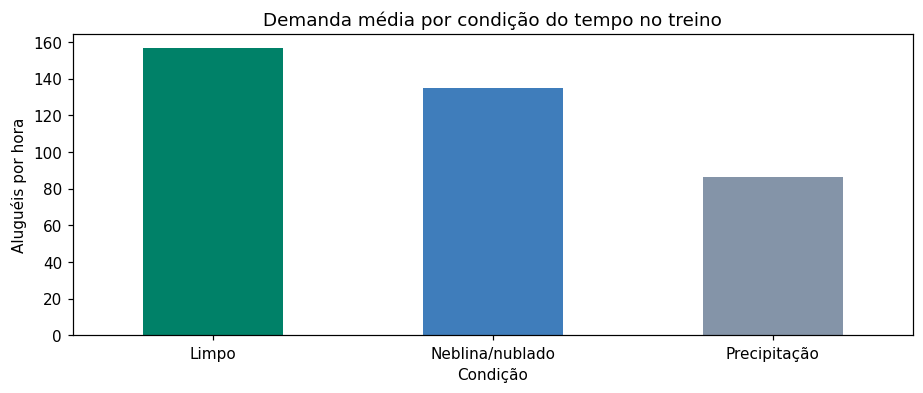

Nas horas com precipitação, a média foi de 86 aluguéis, ante 157 em céu limpo ou parcialmente nublado; essa comparação é descritiva.


In [3]:
clima = treino.assign(clima=np.minimum(treino.weathersit, 3)).groupby("clima").cnt.mean()
ax = clima.rename(index={1: "Limpo", 2: "Neblina/nublado", 3: "Precipitação"}).plot.bar(
    color=["#008168", "#3f7dbb", "#8494a8"], figsize=(8.5, 3.7), rot=0)
ax.set(title="Demanda média por condição do tempo no treino", xlabel="Condição",
       ylabel="Aluguéis por hora")
plt.tight_layout()
from io import BytesIO
from IPython.display import Image
imagem = BytesIO()
ax.figure.savefig(imagem, format='png', dpi=110, bbox_inches='tight')
display(Image(data=imagem.getvalue()))
plt.close(ax.figure)
print(f"Nas horas com precipitação, a média foi de {clima.loc[3]:.0f} aluguéis, "
      f"ante {clima.loc[1]:.0f} em céu limpo ou parcialmente nublado; "
      "essa comparação é descritiva.")

## 2. Baseline × rede neural
O **baseline** prevê a mediana histórica para a mesma hora e o mesmo tipo de dia (útil ou não útil). A **árvore de decisão** de profundidade 8 é uma comparação adicional para o bônus.

As três redes densas usam as mesmas entradas de calendário e clima. As colunas `casual` e `registered` ficaram fora porque, somadas, formam `cnt`, nossa variável alvo. A transformação usa a mesma função no treino e na tela. A normalização adicional é ajustada exclusivamente no treino e fica dentro do modelo Keras.

A métrica é o **erro absoluto médio (MAE)**, em aluguéis por hora. Quanto menor, melhor. Escolhemos a arquitetura pelo MAE de validação. O early stopping monitora a perda de validação e restaura os pesos da melhor época.

In [4]:
X_treino, X_valid = preparar(treino), preparar(validacao)
y_treino = treino.cnt.to_numpy(dtype="float32")
y_valid = validacao.cnt.to_numpy(dtype="float32")

medianas = treino.groupby(["hr", "workingday"]).cnt.median()
mediana_geral = treino.cnt.median()

def baseline(dados):
    chaves = pd.MultiIndex.from_frame(dados[["hr", "workingday"]])
    return medianas.reindex(chaves).fillna(mediana_geral).to_numpy()

arvore = DecisionTreeRegressor(max_depth=8, min_samples_leaf=30, random_state=SEED)
arvore.fit(X_treino, y_treino)
mae_baseline = mean_absolute_error(y_valid, baseline(validacao))
mae_arvore = mean_absolute_error(y_valid, arvore.predict(X_valid))
print(f"Validação | baseline: {mae_baseline:.2f} | árvore: {mae_arvore:.2f}")

Validação | baseline: 119.72 | árvore: 92.36


In [5]:
def lotes(X, y, embaralhar=False):
    dados = tf.data.Dataset.from_tensor_slices((X, y))
    if embaralhar:
        dados = dados.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    opcoes = tf.data.Options()
    opcoes.threading.private_threadpool_size = 2
    return dados.batch(128).with_options(opcoes)

ds_treino = lotes(X_treino, y_treino, embaralhar=True)
ds_valid = lotes(X_valid, y_valid)

normalizacao = keras.layers.Normalization()
normalizacao.adapt(X_treino)

arquiteturas = [(16,), (48, 24), (96, 48)]
historicos, redes, registros = {}, {}, []
for unidades in arquiteturas:
    nome = " × ".join(map(str, unidades))
    camadas = [keras.Input(shape=(X_treino.shape[1],)), normalizacao]
    for largura in unidades:
        camadas.append(keras.layers.Dense(largura, activation="relu"))
    camadas.append(keras.layers.Dense(1, bias_initializer=keras.initializers.Constant(100)))
    rede = keras.Sequential(camadas)
    rede.compile(optimizer=keras.optimizers.Adam(learning_rate=.003), loss="mae")
    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True)
    historico = rede.fit(ds_treino, validation_data=ds_valid, epochs=120,
                         callbacks=[parada], verbose=0).history
    previsoes = np.maximum(0, rede(X_valid, training=False).numpy().ravel())
    registros.append({
        "arquitetura": nome, "parametros_treinaveis": int(sum(
            np.prod(p.shape) for p in rede.trainable_weights)),
        "epocas_executadas": len(historico["loss"]),
        "melhor_epoca": int(np.argmin(historico["val_loss"]) + 1),
        "mae_validacao": mean_absolute_error(y_valid, previsoes),
    })
    historicos[nome] = historico
    redes[nome] = rede

experimentos = pd.DataFrame(registros).sort_values("mae_validacao")
experimentos.to_csv("experimentos.csv", index=False, float_format="%.4f")
display(experimentos.round(2))
melhor_nome = experimentos.iloc[0].arquitetura
melhor_rede = redes[melhor_nome]
print(f"Rede selecionada antes do teste: {melhor_nome}")

  arquitetura  parametros_treinaveis  ...  melhor_epoca  mae_validacao
2     96 × 48                   8737  ...            20          83.89
1     48 × 24                   3217  ...            21          86.49
0          16                    689  ...            73          91.80

[3 rows x 5 columns]

Rede selecionada antes do teste: 96 × 48


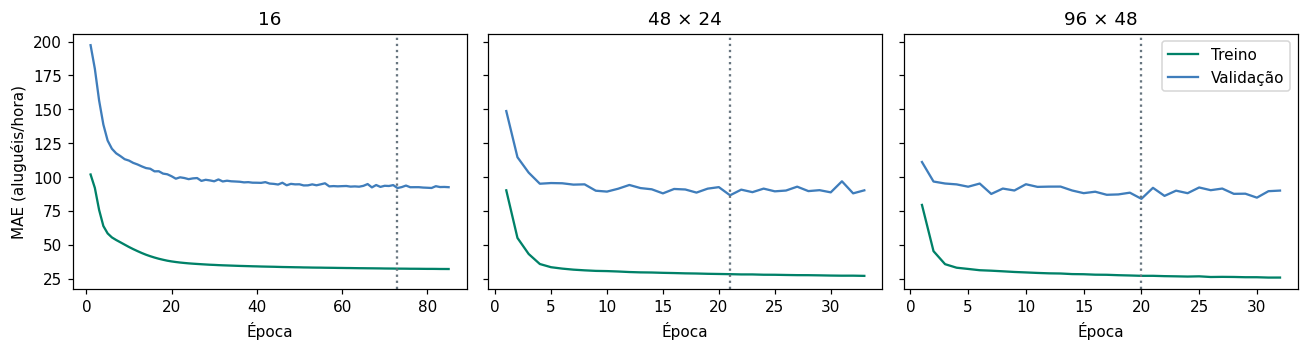

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for eixo, (nome, h) in zip(eixos, historicos.items()):
    epocas = range(1, len(h["loss"]) + 1)
    eixo.plot(epocas, h["loss"], label="Treino", color="#008168")
    eixo.plot(epocas, h["val_loss"], label="Validação", color="#3f7dbb")
    eixo.axvline(np.argmin(h["val_loss"]) + 1, color="#67757f", linestyle=":")
    eixo.set(title=nome, xlabel="Época")
eixos[0].set_ylabel("MAE (aluguéis/hora)")
eixos[-1].legend()
fig.tight_layout()
from io import BytesIO
from IPython.display import Image
imagem = BytesIO()
fig.savefig(imagem, format='png', dpi=110, bbox_inches='tight')
display(Image(data=imagem.getvalue()))
plt.close(fig)

## 3. Abrir o cofre
Após fixar a arquitetura e os demais modelos na validação, fazemos uma única avaliação em lote no teste. Cada modelo gera suas previsões uma vez. Os resultados do teste servem apenas para a comparação final.

In [7]:
X_teste = preparar(teste)
y_teste = teste.cnt.to_numpy()
predicoes = {
    "Baseline": baseline(teste),
    "Árvore de decisão": arvore.predict(X_teste),
    "Rede Keras": np.maximum(0, melhor_rede(X_teste, training=False).numpy().ravel()),
}
metricas = {nome: float(mean_absolute_error(y_teste, estimativa))
            for nome, estimativa in predicoes.items()}
display(pd.Series(metricas, name="MAE de teste (aluguéis/hora)").round(2).to_frame())

frase = (f"No período de teste, a PedalHora estimou o total de aluguéis da rede com "
         f"um erro médio de {metricas['Rede Keras']:.1f} aluguéis por hora, "
         f"comparado com {metricas['Baseline']:.1f} da regra histórica.")
print(frase)
Path("modelo/resultados.json").write_text(json.dumps({
    "arquitetura": melhor_nome, "mae_teste": metricas, "frase": frase,
    "inicio_teste": str(teste.dteday.iloc[0].date()),
    "fim_teste": str(teste.dteday.iloc[-1].date()),
    "n_teste": len(teste)
}, ensure_ascii=False, indent=2), encoding="utf-8")

                   MAE de teste (aluguéis/hora)
Baseline                                 116.63
Árvore de decisão                        104.35
Rede Keras                                89.27

No período de teste, a PedalHora estimou o total de aluguéis da rede com um erro médio de 89.3 aluguéis por hora, comparado com 116.6 da regra histórica.
Out[0]: 415


## 4. Produto
A interface Flask carrega o arquivo salvo e chama a mesma função demonstrada abaixo. A saída é arredondada para exibição. A previsão representa aluguéis para a rede inteira durante a hora escolhida.

In [8]:
from previsao import CENARIO, CLIMAS, carregar_modelo, prever

Path("modelo").mkdir(exist_ok=True)
melhor_rede.save("modelo/pedalhora.keras")
carregar_modelo.cache_clear()
print(f"Cenário histórico simulado: {prever(*CENARIO)} aluguéis previstos.")

Cenário histórico simulado: 582 aluguéis previstos.


In [9]:
from ipywidgets import Checkbox, Dropdown, FloatSlider, IntSlider, Text, interact_manual

@interact_manual(
    data=Text(value=CENARIO[0], description="Data"),
    hora=IntSlider(value=17, min=0, max=23, description="Hora"),
    temperatura=FloatSlider(value=22, min=0, max=41, description="Temp. °C"),
    umidade=IntSlider(value=55, min=0, max=100, description="Umidade %"),
    vento=IntSlider(value=14, min=0, max=67, description="Vento km/h"),
    clima=Dropdown(options=[(texto, codigo) for codigo, texto in CLIMAS.items()],
                   description="Tempo"),
    feriado=Checkbox(value=False, description="Feriado"),
)
def simular(data, hora, temperatura, umidade, vento, clima, feriado):
    try:
        print(f"Previsão: {prever(data, hora, temperatura, umidade, vento, clima, feriado)} aluguéis.")
    except ValueError as erro:
        print(erro)

interactive(children=(Text(value='2012-10-16', continuous_update=False, description='Data'), IntSlider(value=1…

## 5. Documentação
O [README](README.md) contém a instalação, os resultados, o print e a declaração de uso de IA. O [MODEL_CARD](MODEL_CARD.md) detalha o treinamento e os limites de uso.